ARIMAX

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 0)   Log Likelihood              -50622.444
Date:                Fri, 30 Jan 2026   AIC                         101268.888
Time:                        13:30:33   BIC                         101362.736
Sample:                    01-01-2022   HQIC                        101299.716
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3291      0.003    423.431      0.000       1.323       1.335
SO2                    0.0938      0.003     27.794      0.000       0.087       0.100
CO                  

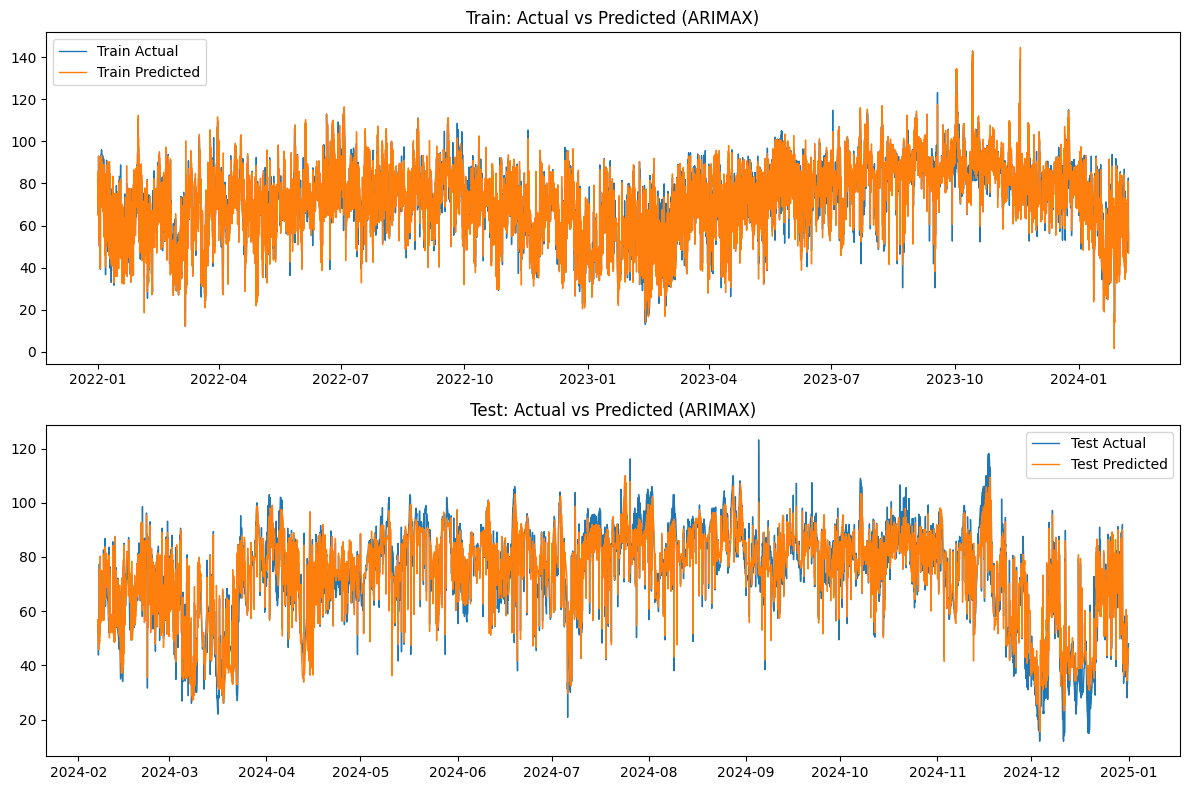

In [8]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")
import os

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2', 'Suhu Udara', 'Radiasi Matahari', 'Suhu Titik Embun',
    'Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

train_size = int(len(df) * 0.7)
y_train, y_test = y[:train_size], y[train_size:]
exog_train, exog_test = X[:train_size], X[train_size:]

# =========================
# 2. Fit model ARIMAX
# =========================
order = (0, 1, 0)

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 3. Prediksi
# =========================
pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=exog_train
)

pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=exog_test
)

# =========================
# 4. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train, pred_train, "Train")
print_metrics(y_test, pred_test, "Test")

# =========================
# 5. Plot hasil
# =========================
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train, label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test, label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

plt.tight_layout()
plt.show()


                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 1)   Log Likelihood              -49094.064
Date:                Fri, 26 Dec 2025   AIC                          98214.128
Time:                        13:36:04   BIC                          98315.796
Sample:                    01-01-2022   HQIC                         98247.525
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3109      0.003    378.801      0.000       1.304       1.318
SO2                    0.0918      0.004     24.210      0.000       0.084       0.099
CO                  

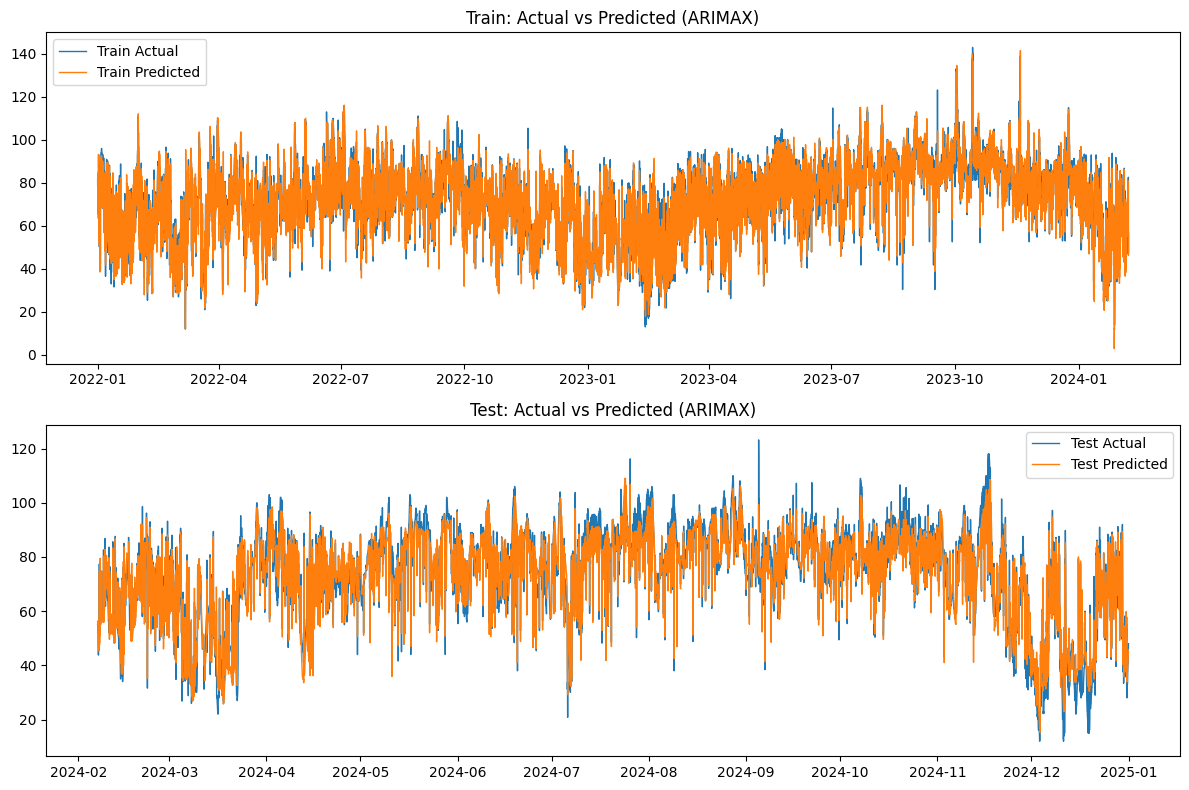

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/SARIMAX-SVR/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2', 'Suhu Udara', 'Radiasi Matahari', 'Suhu Titik Embun',
    'Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

train_size = int(len(df) * 0.7)
y_train, y_test = y[:train_size], y[train_size:]
exog_train, exog_test = X[:train_size], X[train_size:]

# =========================
# 2. Fit model ARIMAX
# =========================
order = (0, 1, 1)

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 3. Prediksi
# =========================
pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=exog_train
)

pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=exog_test
)

# =========================
# 4. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train, pred_train, "Train")
print_metrics(y_test, pred_test, "Test")

# =========================
# 5. Plot hasil
# =========================
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train, label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test, label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -49010.748
Date:                Fri, 26 Dec 2025   AIC                          98049.496
Time:                        13:36:52   BIC                          98158.984
Sample:                    01-01-2022   HQIC                         98085.461
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3103      0.004    371.961      0.000       1.303       1.317
SO2                    0.0952      0.004     24.790      0.000       0.088       0.103
CO                  

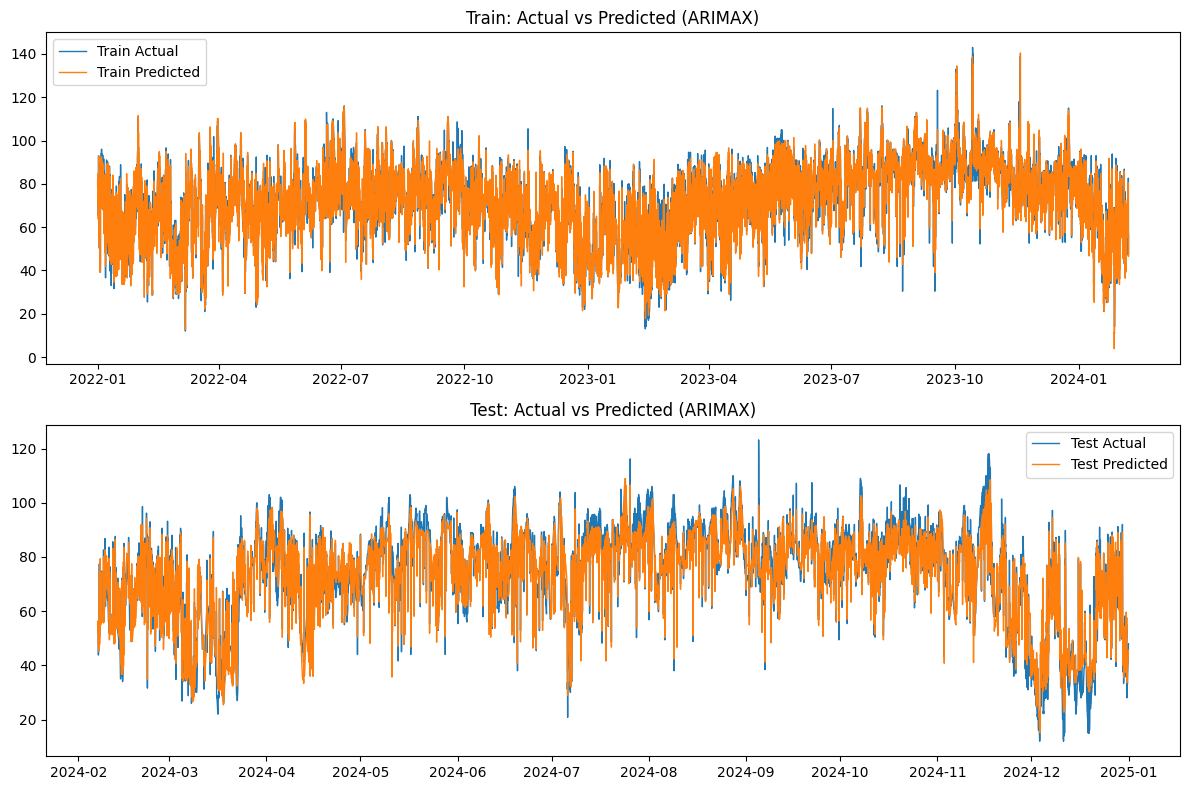

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/SARIMAX-SVR/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2', 'Suhu Udara', 'Radiasi Matahari', 'Suhu Titik Embun',
    'Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

train_size = int(len(df) * 0.7)
y_train, y_test = y[:train_size], y[train_size:]
exog_train, exog_test = X[:train_size], X[train_size:]

# =========================
# 2. Fit model ARIMAX
# =========================
order = (0, 1, 2)

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 3. Prediksi
# =========================
pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=exog_train
)

pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=exog_test
)

# =========================
# 4. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train, pred_train, "Train")
print_metrics(y_test, pred_test, "Test")

# =========================
# 5. Plot hasil
# =========================
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train, label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test, label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

plt.tight_layout()
plt.show()

Drop Variabel Eksogen Suhu Udara dan Suhu Titik Embun

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -49010.833
Date:                Fri, 30 Jan 2026   AIC                          98045.666
Time:                        13:56:28   BIC                          98139.513
Sample:                    01-01-2022   HQIC                         98076.494
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3106      0.004    373.287      0.000       1.304       1.317
SO2                    0.0947      0.004     24.681      0.000       0.087       0.102
CO                  

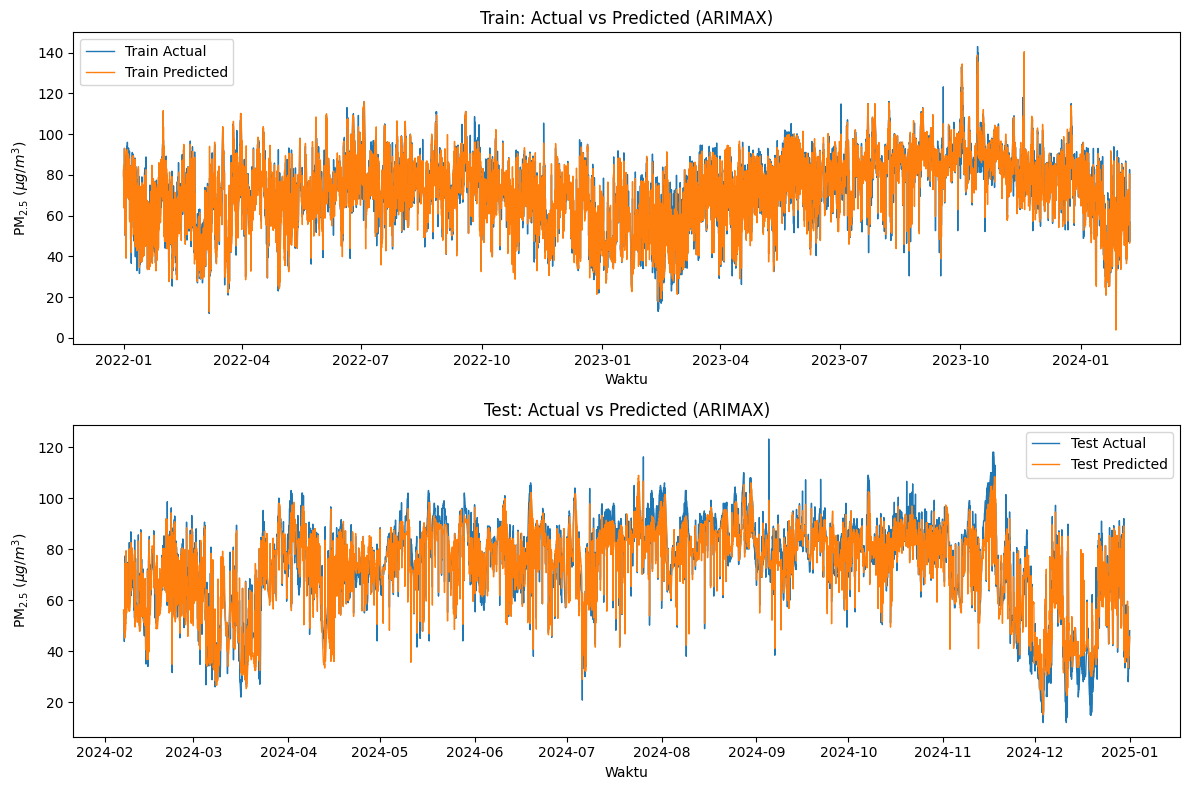

In [10]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Radiasi Matahari','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']]

train_size = int(len(df) * 0.7)
y_train, y_test = y[:train_size], y[train_size:]
exog_train, exog_test = X[:train_size], X[train_size:]

# =========================
# 2. Fit model ARIMAX
# =========================
order = (0, 1, 2)

model = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 3. Prediksi
# =========================
pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=exog_train
)

pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=exog_test
)

# =========================
# 4. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train, pred_train, "Train")
print_metrics(y_test, pred_test, "Test")

# =========================
# 5. Plot hasil
# =========================
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train, label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test, label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()



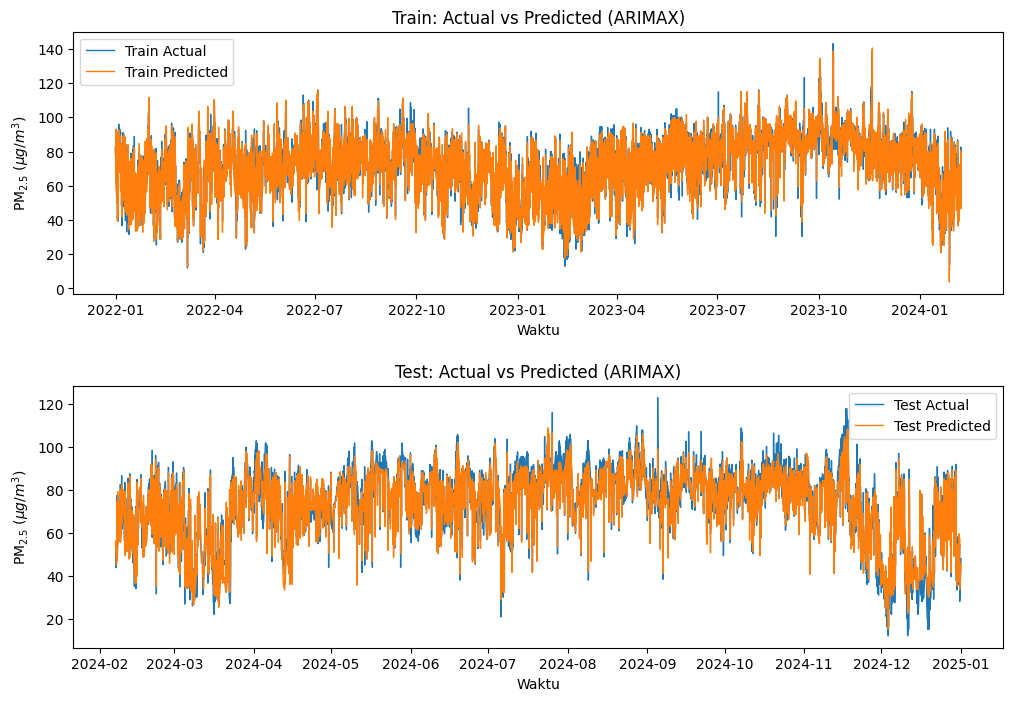

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar/ARIMAX_Train_Test.jpeg


In [16]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "ARIMAX_Train_Test.jpeg")

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train, label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test, label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)


ARIMAX-SVR

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -49010.833
Date:                Sun, 04 Jan 2026   AIC                          98045.666
Time:                        08:44:36   BIC                          98139.513
Sample:                    01-01-2022   HQIC                         98076.494
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3106      0.004    373.287      0.000       1.304       1.317
SO2                    0.0947      0.004     24.681      0.000       0.087       0.102
CO                  

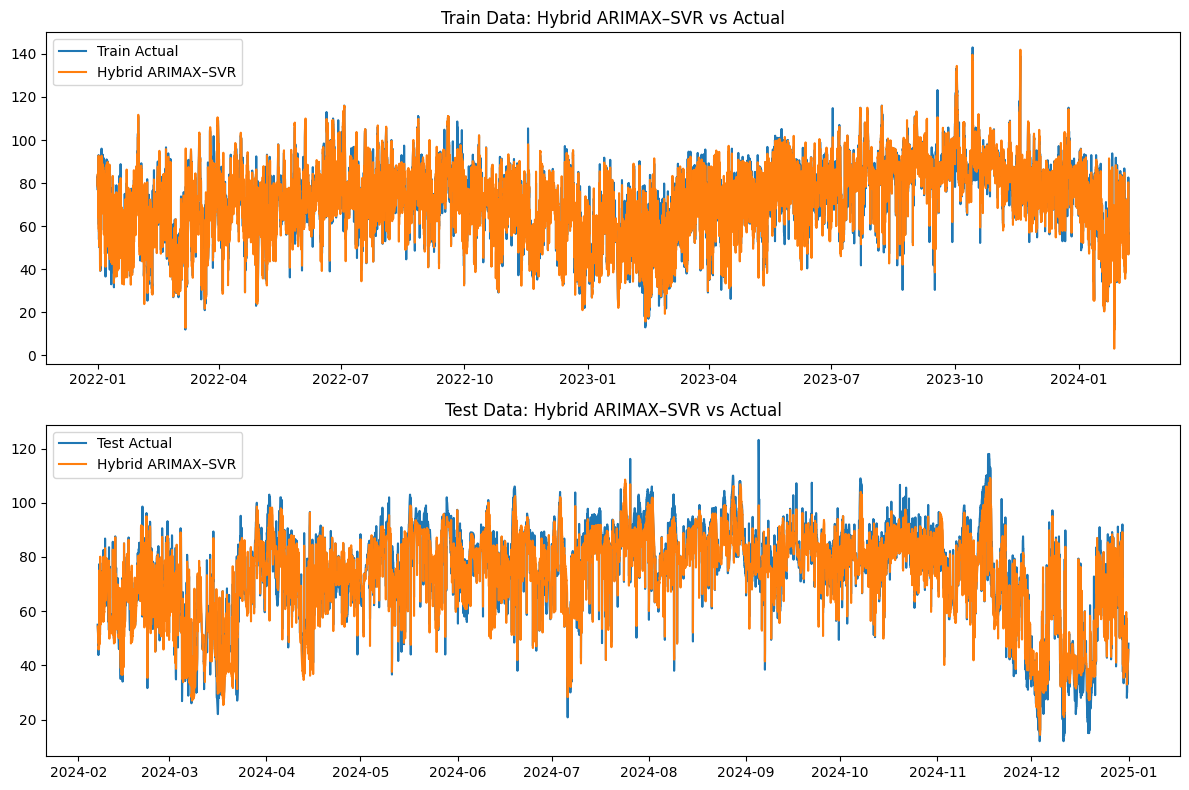

In [ ]:
# =====================================================
# IMPORT LIBRARY
# =====================================================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Radiasi Matahari','Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

# =====================================================
# 2. TRAIN TEST SPLIT (TIME SERIES)
# =====================================================
train_size = int(len(df) * 0.7)

y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]

# =====================================================
# 3. MODEL ARIMAX
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =====================================================
# 4. PREDIKSI ARIMAX
# =====================================================
arimax_pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=X_train
)

arimax_pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=X_test
)

# =====================================================
# 5. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train - arimax_pred_train
residual_test  = y_test  - arimax_pred_test

# =====================================================
# 6. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=1):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=1)
df_res_test  = create_lagged_residual(residual_test,  n_lags=1)

X_train_res = df_res_train[['lag1']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1']]
y_test_res = df_res_test['residual']

# =====================================================
# 7. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 8. MODEL SVR (TANPA TUNING)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr_base = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr_base,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("\nBest SVR parameters:", grid_search.best_params_)

svr = grid_search.best_estimator_

# =====================================================
# 9. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 10. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_pred_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_pred_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 11. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(y_train.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(y_train.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
)
print("R2  :", r2_score(y_test.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 12. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# --- Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual')
ax[0].plot(
    y_train.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# --- Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual')
ax[1].plot(
    y_test.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -49010.833
Date:                Sun, 04 Jan 2026   AIC                          98045.666
Time:                        10:44:35   BIC                          98139.513
Sample:                    01-01-2022   HQIC                         98076.494
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3106      0.004    373.287      0.000       1.304       1.317
SO2                    0.0947      0.004     24.681      0.000       0.087       0.102
CO                  

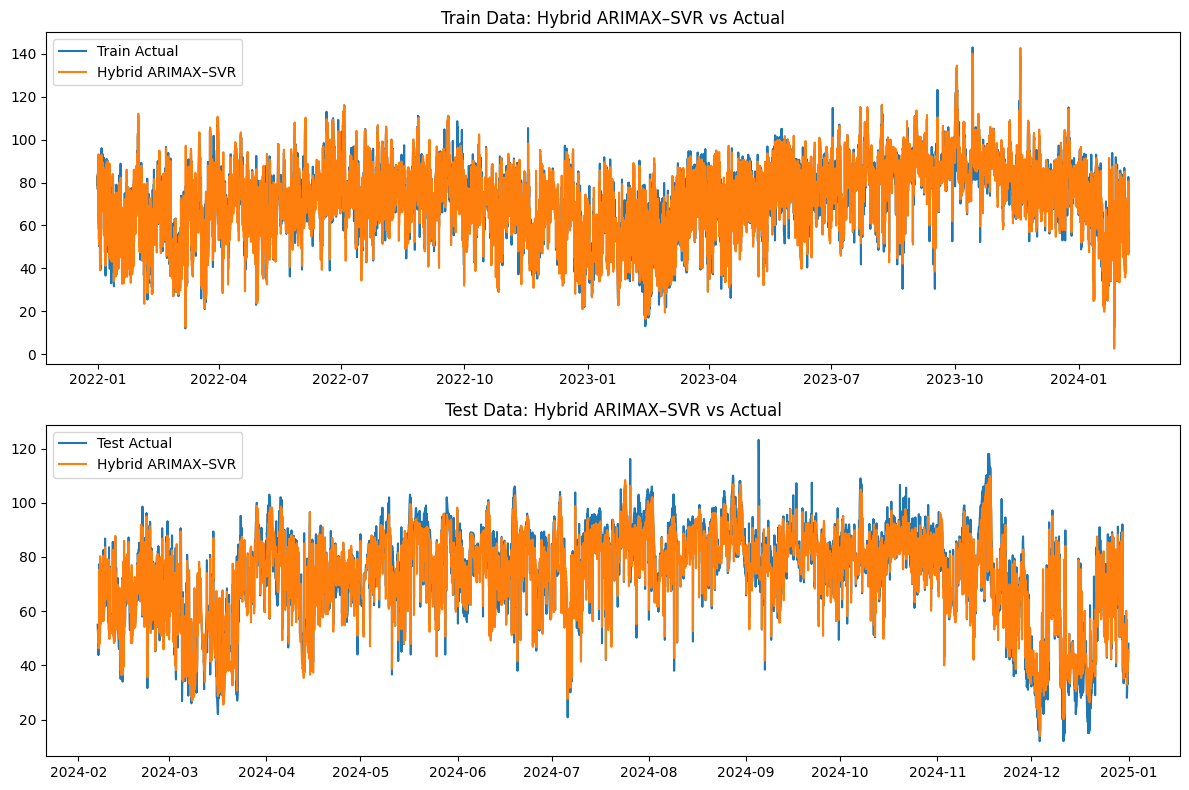

In [ ]:
# =====================================================
# IMPORT LIBRARY
# =====================================================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Radiasi Matahari','Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

# =====================================================
# 2. TRAIN TEST SPLIT (TIME SERIES)
# =====================================================
train_size = int(len(df) * 0.7)

y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]

# =====================================================
# 3. MODEL ARIMAX
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =====================================================
# 4. PREDIKSI ARIMAX
# =====================================================
arimax_pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=X_train
)

arimax_pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=X_test
)

# =====================================================
# 5. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train - arimax_pred_train
residual_test  = y_test  - arimax_pred_test

# =====================================================
# 6. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=2):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=2)
df_res_test  = create_lagged_residual(residual_test,  n_lags=2)

X_train_res = df_res_train[['lag1','lag2']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1','lag2']]
y_test_res = df_res_test['residual']

# =====================================================
# 7. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 8. MODEL SVR (TANPA TUNING)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr_base = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr_base,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("\nBest SVR parameters:", grid_search.best_params_)

svr = grid_search.best_estimator_

# =====================================================
# 9. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 10. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_pred_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_pred_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 11. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(y_train.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(y_train.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
)
print("R2  :", r2_score(y_test.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 12. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# --- Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual')
ax[0].plot(
    y_train.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# --- Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual')
ax[1].plot(
    y_test.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                  PM2.5   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -49010.833
Date:                Fri, 30 Jan 2026   AIC                          98045.666
Time:                        14:17:07   BIC                          98139.513
Sample:                    01-01-2022   HQIC                         98076.494
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   1.3106      0.004    373.287      0.000       1.304       1.317
SO2                    0.0947      0.004     24.681      0.000       0.087       0.102
CO                  

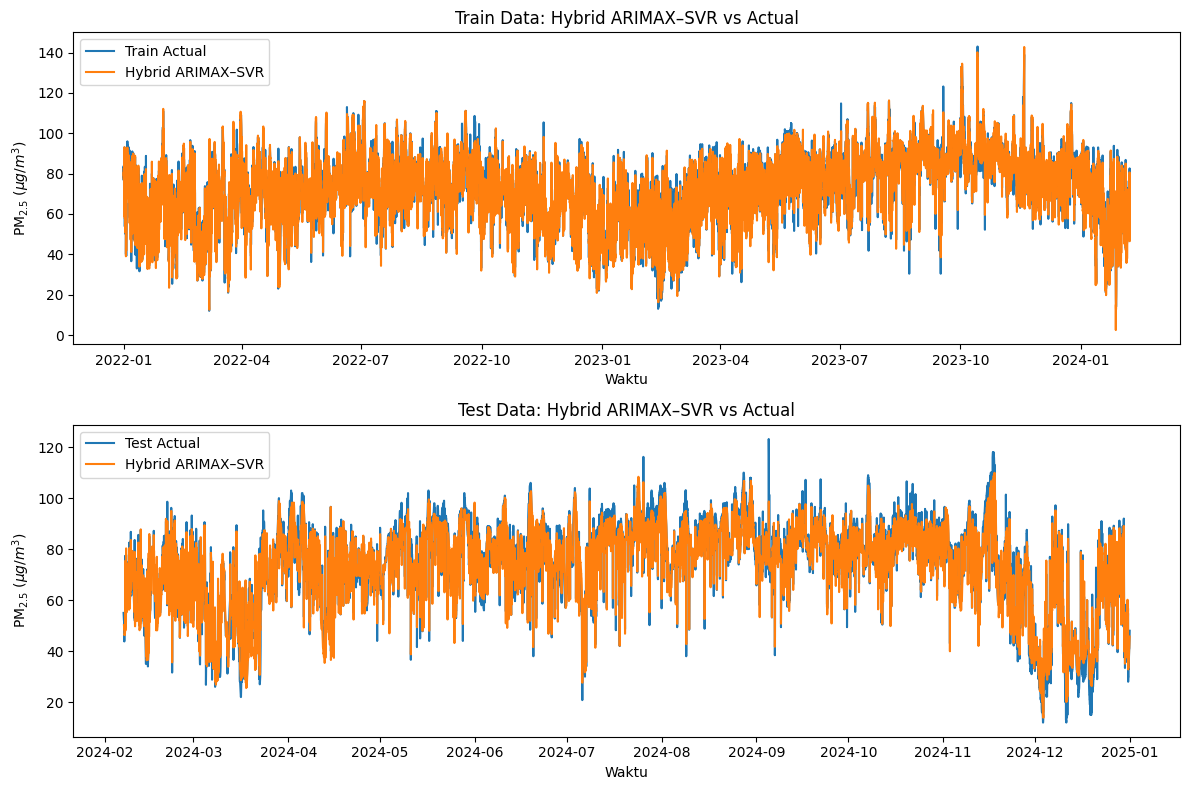

In [2]:
# =====================================================
# IMPORT LIBRARY
# =====================================================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Radiasi Matahari','Curah Hujan', 'Kelembaban Relatif', 'Kecepatan Angin']]

# =====================================================
# 2. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]

# =====================================================
# 3. MODEL ARIMAX
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =====================================================
# 4. PREDIKSI ARIMAX
# =====================================================
arimax_pred_train = result.predict(
    start=y_train.index[0],
    end=y_train.index[-1],
    exog=X_train
)

arimax_pred_test = result.predict(
    start=y_test.index[0],
    end=y_test.index[-1],
    exog=X_test
)

# =====================================================
# 5. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train - arimax_pred_train
residual_test  = y_test  - arimax_pred_test

# =====================================================
# 6. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=3):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=3)
df_res_test  = create_lagged_residual(residual_test,  n_lags=3)

X_train_res = df_res_train[['lag1', 'lag2', 'lag3']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1', 'lag2', 'lag3']]
y_test_res = df_res_test['residual']

# =====================================================
# 7. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 8. MODEL SVR (TANPA TUNING)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr_base = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr_base,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("\nBest SVR parameters:", grid_search.best_params_)

svr = grid_search.best_estimator_

# =====================================================
# 9. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 10. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_pred_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_pred_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 11. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(y_train.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(y_train.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test.iloc[-len(hybrid_test):], hybrid_test))
)
print("R2  :", r2_score(y_test.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 12. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual')
ax[0].plot(
    y_train.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual')
ax[1].plot(
    y_test.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()

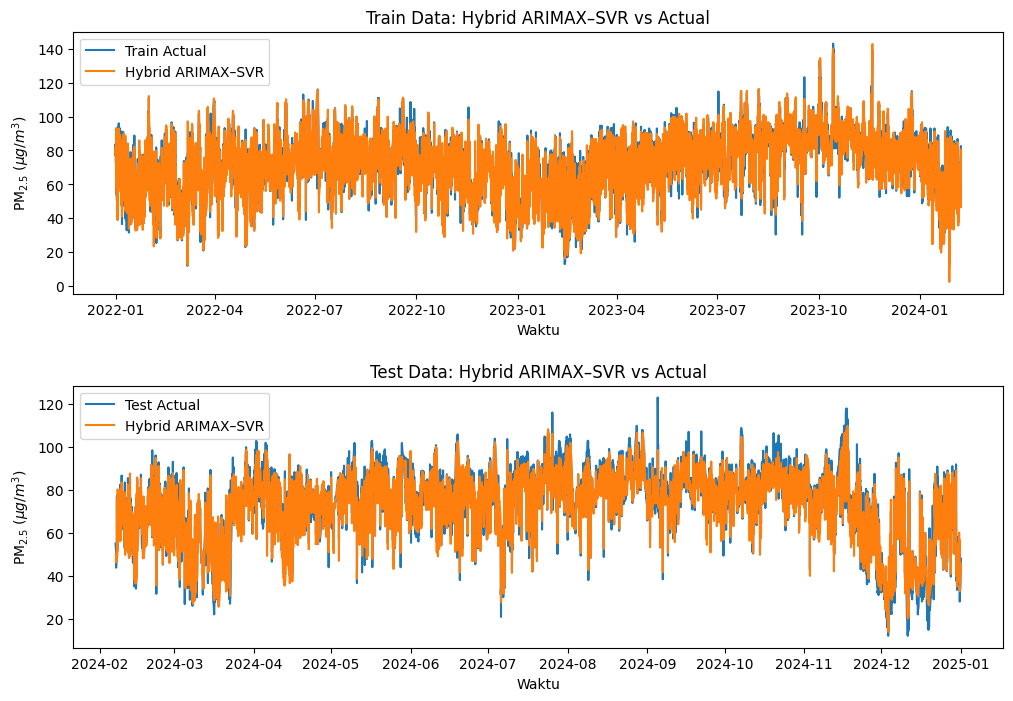

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar/Hybrid_Train_Test.jpeg


In [5]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "Hybrid_Train_Test.jpeg")

fig, ax = plt.subplots(2, 1, figsize=(12, 8))
# --- Plot Train ---
ax[0].plot(y_train.index, y_train, label='Train Actual')
ax[0].plot(
    y_train.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test.index, y_test, label='Test Actual')
ax[1].plot(
    y_test.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)

SVR

Fitting 5 folds for each of 64 candidates, totalling 320 fits

================ BEST PARAMETER ================
{'C': 10, 'epsilon': 0.0001, 'gamma': 0.01}

================ PERFORMANCE RESULT ================

       Station  Train RMSE  Train MAE  Train R2  Test RMSE  Test MAE   Test R2
0  Bundaran HI    5.298991   3.714297  0.909207   4.856868  3.590382  0.925536


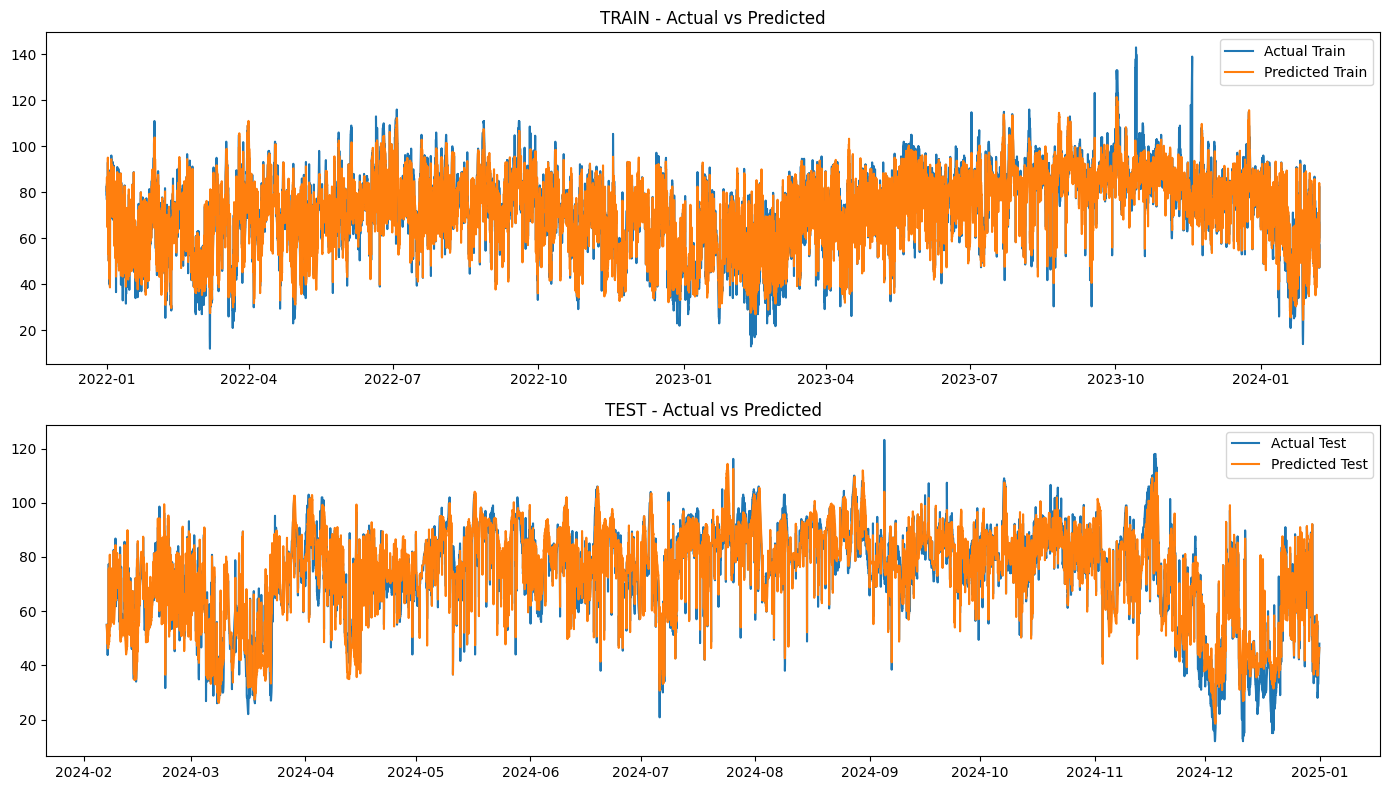


============ FEATURE IMPORTANCE ============

              Feature  Importance Mean  Importance Std
4                PM10         1.605103        0.018688
5                 SO2         0.007457        0.000428
2  Kelembaban Relatif         0.006835        0.000307
0    Radiasi Matahari         0.003587        0.000228
3     Kecepatan Angin         0.002363        0.000082
7                  O3         0.001579        0.000192
8                 NO2         0.000987        0.000216
6                  CO         0.000786        0.000246
1         Curah Hujan         0.000722        0.000114


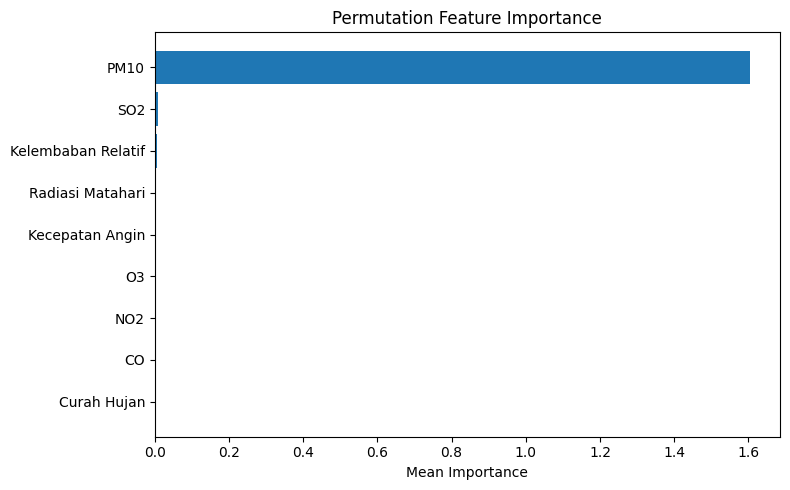

In [ ]:
# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/SARIMAX-SVR/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path)

# ===============================
# DEFINISI KOLOM
# ===============================
target_col = 'PM2.5'

meteorology_cols = ['Radiasi Matahari','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']
pollutant_cols = ['PM10','SO2','CO','O3','NO2']

feature_cols = meteorology_cols + pollutant_cols

# ===============================
# PREPROCESSING
# ===============================
df = df.dropna().reset_index(drop=True)

# ===============================
# TRAIN - TEST SPLIT
# ===============================
split_index = int(len(df) * 0.7)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

datetime_train = train_df['datetime']
datetime_test  = test_df['datetime']

# ===============================
# SCALING DATA
# ===============================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1,1)).ravel()

# ===============================
# HYPERPARAMETER TUNING SVR
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [1, 4, 7, 10],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_scaled, y_train_scaled)

print("\n================ BEST PARAMETER ================")
print(grid.best_params_)

svr = grid.best_estimator_

# ===============================
# PREDIKSI MODEL
# ===============================
y_train_pred_scaled = svr.predict(X_train_scaled)
y_test_pred_scaled  = svr.predict(X_test_scaled)

# Inverse scaling
y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled.reshape(-1,1))
y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled.reshape( -1,1))

y_train_actual = y_train.values.reshape(-1,1)
y_test_actual  = y_test.values.reshape(-1,1)

# ===============================
# EVALUASI AKURASI
# ===============================
train_rmse = math.sqrt(mean_squared_error(y_train_actual, y_train_pred))
train_mae  = mean_absolute_error(y_train_actual, y_train_pred)
train_r2   = r2_score(y_train_actual, y_train_pred)

test_rmse = math.sqrt(mean_squared_error(y_test_actual, y_test_pred))
test_mae  = mean_absolute_error(y_test_actual, y_test_pred)
test_r2   = r2_score(y_test_actual, y_test_pred)

results_df = pd.DataFrame([{
    'Station': 'Bundaran HI',
    'Train RMSE': train_rmse,
    'Train MAE': train_mae,
    'Train R2': train_r2,
    'Test RMSE': test_rmse,
    'Test MAE': test_mae,
    'Test R2': test_r2
}])

print("\n================ PERFORMANCE RESULT ================\n")
print(results_df)

# ===============================
# VISUALISASI ACTUAL VS PREDIKSI
# ===============================
plt.style.use('default')
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=False)

# TRAIN
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title("TRAIN - Actual vs Predicted")
ax[0].legend()

# TEST
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title("TEST - Actual vs Predicted")
ax[1].legend()

plt.tight_layout()
plt.show()

# ===============================
# PERMUTATION FEATURE IMPORTANCE
# ===============================
importance = permutation_importance(
    svr, X_test_scaled, y_test_scaled,
    n_repeats=30, random_state=42, scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance Mean': importance.importances_mean,
    'Importance Std' : importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print("\n============ FEATURE IMPORTANCE ============\n")
print(importance_df)

# Plot
plt.figure(figsize=(8,5))
plt.barh(importance_df['Feature'], importance_df['Importance Mean'])
plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Importance")
plt.tight_layout()
plt.show()

Fitting 5 folds for each of 96 candidates, totalling 480 fits

================ BEST PARAMETER ================
{'C': 20, 'epsilon': 0.001, 'gamma': 0.01}

================ PERFORMANCE RESULT ================

       Station  Train RMSE  Train MAE  Train R2  Test RMSE  Test MAE   Test R2
0  Bundaran HI     5.25114   3.675424  0.910839   4.829288  3.556481  0.926379


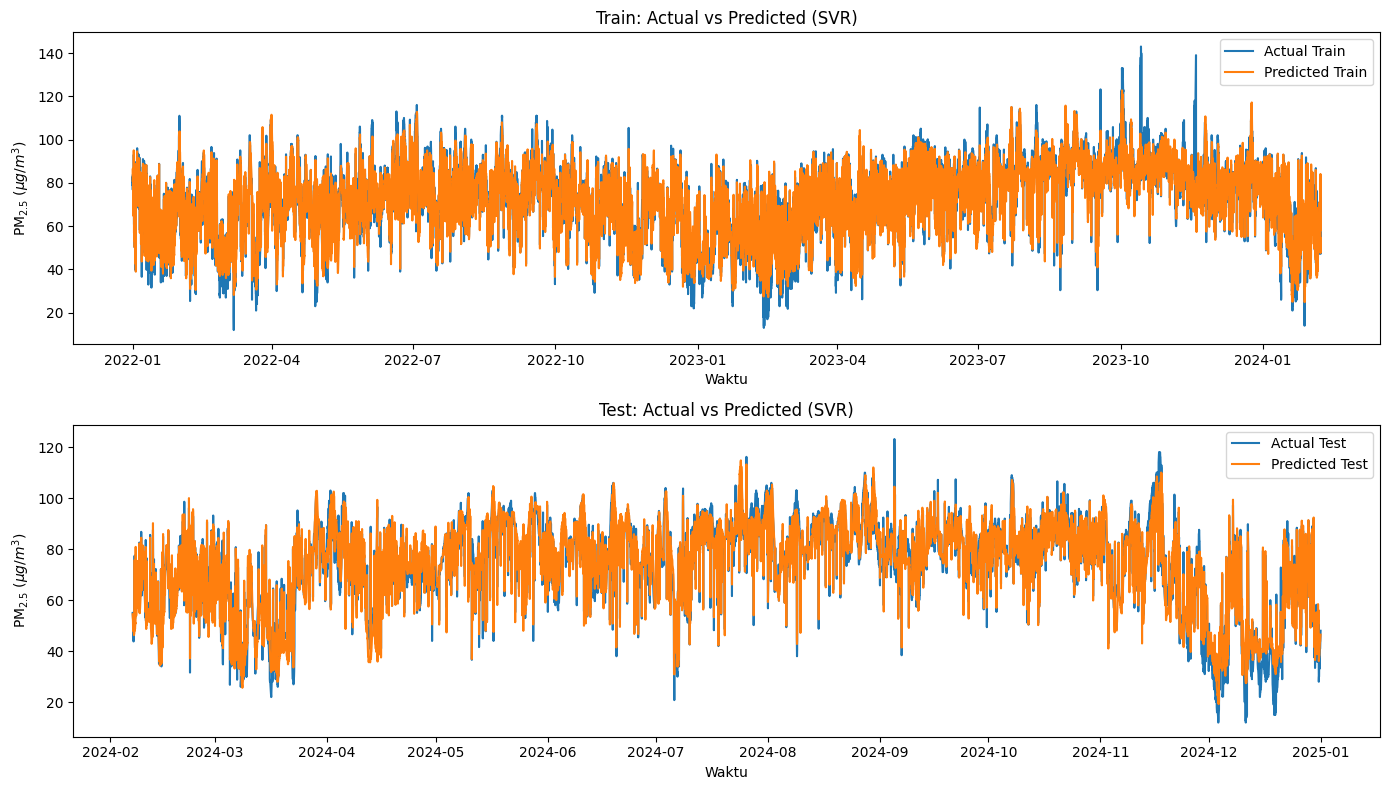


============ FEATURE IMPORTANCE ============

              Feature  Importance Mean  Importance Std
4                PM10         1.604628        0.018772
5                 SO2         0.009555        0.000575
2  Kelembaban Relatif         0.006649        0.000314
3     Kecepatan Angin         0.003796        0.000132
0    Radiasi Matahari         0.002846        0.000235
8                 NO2         0.001515        0.000262
6                  CO         0.001412        0.000237
7                  O3         0.001119        0.000224
1         Curah Hujan         0.000718        0.000114


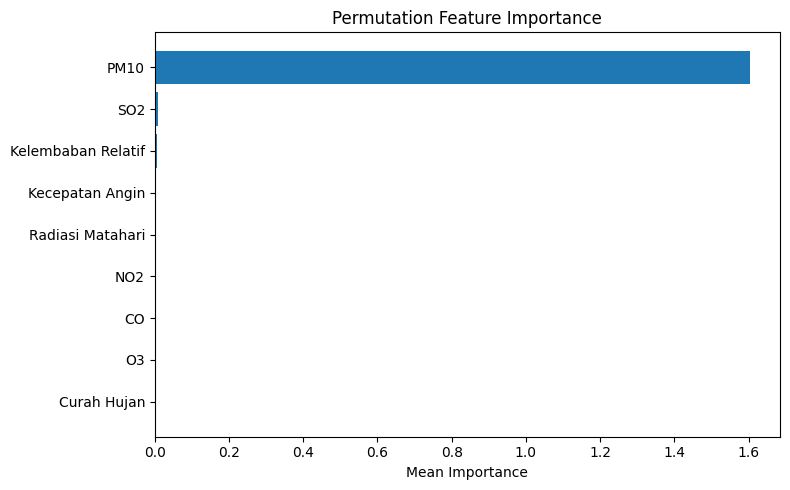

In [7]:
# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path)

# ===============================
# DEFINISI KOLOM
# ===============================
target_col = 'PM2.5'

meteorology_cols = ['Radiasi Matahari','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']
pollutant_cols = ['PM10','SO2','CO','O3','NO2']

feature_cols = meteorology_cols + pollutant_cols

# ===============================
# PREPROCESSING
# ===============================
df = df.dropna().reset_index(drop=True)

# ===============================
# TRAIN - TEST SPLIT
# ===============================
split_index = int(len(df) * 0.7)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

datetime_train = train_df['datetime']
datetime_test  = test_df['datetime']

# ===============================
# SCALING DATA
# ===============================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1,1)).ravel()

# ===============================
# HYPERPARAMETER TUNING SVR
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_scaled, y_train_scaled)

print("\n================ BEST PARAMETER ================")
print(grid.best_params_)

svr = grid.best_estimator_

# ===============================
# PREDIKSI MODEL
# ===============================
y_train_pred_scaled = svr.predict(X_train_scaled)
y_test_pred_scaled  = svr.predict(X_test_scaled)

# Inverse scaling
y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled.reshape(-1,1))
y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled.reshape( -1,1))

y_train_actual = y_train.values.reshape(-1,1)
y_test_actual  = y_test.values.reshape(-1,1)

# ===============================
# EVALUASI AKURASI
# ===============================
train_rmse = math.sqrt(mean_squared_error(y_train_actual, y_train_pred))
train_mae  = mean_absolute_error(y_train_actual, y_train_pred)
train_r2   = r2_score(y_train_actual, y_train_pred)

test_rmse = math.sqrt(mean_squared_error(y_test_actual, y_test_pred))
test_mae  = mean_absolute_error(y_test_actual, y_test_pred)
test_r2   = r2_score(y_test_actual, y_test_pred)

results_df = pd.DataFrame([{
    'Station': 'Bundaran HI',
    'Train RMSE': train_rmse,
    'Train MAE': train_mae,
    'Train R2': train_r2,
    'Test RMSE': test_rmse,
    'Test MAE': test_mae,
    'Test R2': test_r2
}])

print("\n================ PERFORMANCE RESULT ================\n")
print(results_df)

# ===============================
# VISUALISASI ACTUAL VS PREDIKSI
# ===============================
plt.style.use('default')
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=False)

# TRAIN
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title('Train: Actual vs Predicted (SVR)', fontsize=12)
ax[0].legend()

# TEST
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title('Test: Actual vs Predicted (SVR)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()

# ===============================
# PERMUTATION FEATURE IMPORTANCE
# ===============================
importance = permutation_importance(
    svr, X_test_scaled, y_test_scaled,
    n_repeats=30, random_state=42, scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance Mean': importance.importances_mean,
    'Importance Std' : importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print("\n============ FEATURE IMPORTANCE ============\n")
print(importance_df)

# Plot
plt.figure(figsize=(8,5))
plt.barh(importance_df['Feature'], importance_df['Importance Mean'])
plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Importance")
plt.tight_layout()
plt.show()

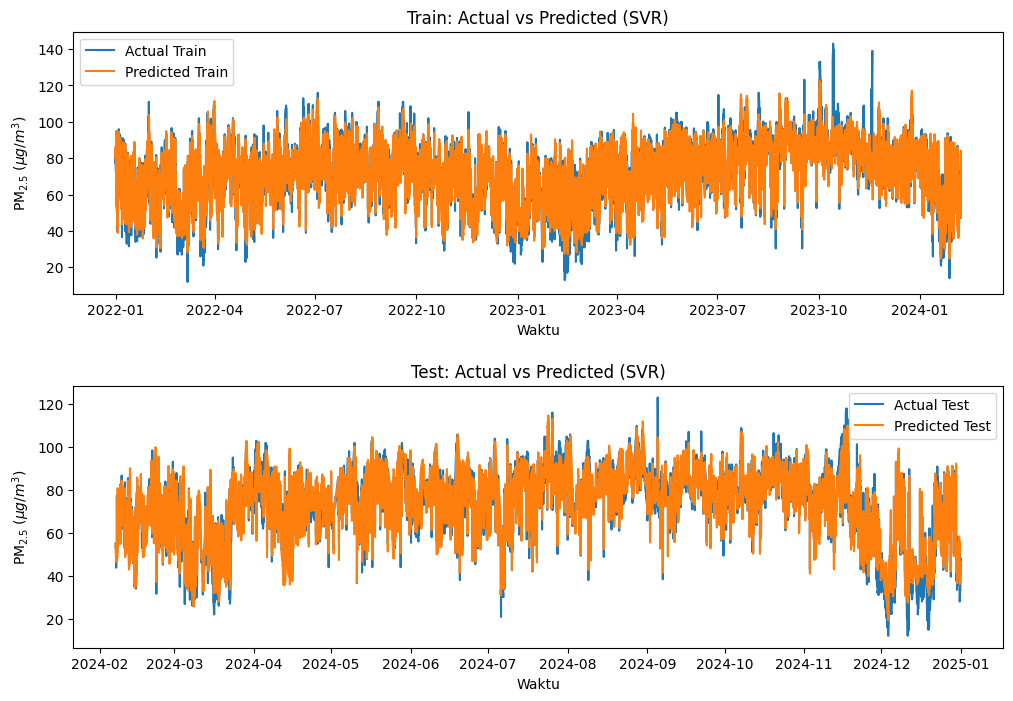

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar/SVR_Train_Test.jpeg


In [8]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/MBKM/Meteorologi + Pollutant/Model ARIMAX, SVR, Hybrid ARIMAX-SVR/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "SVR_Train_Test.jpeg")

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title('Train: Actual vs Predicted (SVR)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title('Test: Actual vs Predicted (SVR)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)